# Chest X-ray Generation with a Convolutional VAE
ECE 285 - Homework 1

This notebook implements an unconditional convolutional VAE in PyTorch and compares
regularization strength, decoder architecture, and continued training.

## Running the notebook

The default settings display the recorded experimental results without downloading the dataset
or starting training. Figures are embedded and are also visible without running cells.

- **Train from scratch:** set `RUN_TRAINING = True` in Section 1.
- **Train and evaluate:** set both `RUN_TRAINING` and `RUN_EVALUATION` to `True`.
- **Evaluate existing original checkpoints:** enable only `RUN_EVALUATION`.
- **Repeat the additional beta sweep:** enable `RUN_BETA_SWEEP` and keep the companion
  `hw1_beta_sweep.py` next to this notebook. In Colab, upload that script to the runtime Files panel.

New original-protocol runs use `HW1_VAE/reproduction_runs`; additional sweep reruns use
`HW1_VAE/reproduction_beta_sweep`. Recorded results and existing checkpoints are kept separate.
Training resumes from saved checkpoints. Select a GPU runtime for training and metric evaluation.

Recorded metrics below come from completed Colab experiments. Fresh runs can differ because the
original interactive sessions consumed random numbers in diagnostic cells. Reorganizing the code
does not recreate those sessions' complete RNG trajectory.

## 1. Dependencies and configuration
The recorded GPU environment used PyTorch 2.11.0+cu130, torchvision 0.26.0+cu130,
and pytorch-ignite 0.5.5. In Colab, retain its matched PyTorch/torchvision installation.


In [ ]:
import importlib.util
import subprocess
import sys

extra_dependencies = {
    "kagglehub": "kagglehub",
    "ignite": "pytorch-ignite==0.5.5",
    "scipy": "scipy",
    "tqdm": "tqdm",
}
missing = [package for module, package in extra_dependencies.items()
           if importlib.util.find_spec(module) is None]
if importlib.util.find_spec("ignite") is not None:
    from importlib.metadata import version
    if version("pytorch-ignite") != "0.5.5":
        missing.append("pytorch-ignite==0.5.5")
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])


In [ ]:
import copy
import json
import random
import re
import shutil
import time
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import DataLoader, Dataset

SEED = 42
IMAGE_SIZE = 64
LATENT_DIM = 32
BATCH_SIZE = 64
OBS_STD = 0.1
LEARNING_RATE = 1e-3
EVAL_SEED = 2026
EXPERIMENTS = ["baseline", "beta4", "resize_beta4", "beta4_extended"]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Existing experimental checkpoints remain separate from new training runs.
RUN_TRAINING = False
RUN_EVALUATION = False
RUN_BETA_SWEEP = False
SAVE_DIR = Path("/content/drive/MyDrive/HW1_VAE")
REPRODUCTION_DIR = SAVE_DIR / "reproduction_runs"
ACTIVE_DIR = REPRODUCTION_DIR if RUN_TRAINING else SAVE_DIR

if RUN_TRAINING or RUN_EVALUATION:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except ImportError:
        pass
    ACTIVE_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", device)
print("Training enabled:", RUN_TRAINING)
print("Evaluation enabled:", RUN_EVALUATION)
print("Additional beta sweep enabled:", RUN_BETA_SWEEP)


## 2. Dataset and split
The original training set contains 5,216 images. A seed-42 holdout of 10% of filename groups
within each class produces 4,699 training and 517 validation images. The original 16-image validation
folder is unused. Filename-group separation does not establish independently verified patient identities.
Images are grayscale, resized directly to 64 x 64 using bilinear interpolation, and scaled to [0, 1].
Labels are used only to form the split; the VAE is unconditional.


In [ ]:
def preprocess_image(path):
    with Image.open(path) as image:
        image = image.convert("L").resize(
            (IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR
        )
        pixels = np.array(image, dtype=np.float32) / 255.0
    return torch.from_numpy(pixels).unsqueeze(0)


class XRayDataset(Dataset):
    def __init__(self, files):
        self.files = list(files)

    def __len__(self):
        return len(self.files)

    def __getitem__(self, index):
        return preprocess_image(self.files[index])


def image_files(folder):
    return sorted(p for p in folder.rglob("*")
                  if p.is_file() and p.suffix.lower() in {".jpeg", ".jpg", ".png"})


def get_group(path):
    pattern = (r"(person\d+)_" if path.parent.name == "PNEUMONIA"
               else r"((?:NORMAL2-)?IM-\d+)-")
    match = re.match(pattern, path.stem, flags=re.IGNORECASE)
    if match is None:
        raise ValueError(f"Unrecognized filename: {path.name}")
    return f"{path.parent.name}/{match.group(1).upper()}"


def prepare_data(root, destination):
    destination.mkdir(parents=True, exist_ok=True)
    all_files = image_files(root / "train")
    train_files, validation_files = [], []
    rng = random.Random(SEED)
    for category in ["NORMAL", "PNEUMONIA"]:
        groups = defaultdict(list)
        for path in all_files:
            if path.parent.name == category:
                groups[get_group(path)].append(path)
        group_ids = sorted(groups)
        rng.shuffle(group_ids)
        n_validation = max(1, round(0.10 * len(group_ids)))
        validation_groups = set(group_ids[:n_validation])
        for group_id in sorted(groups):
            target = validation_files if group_id in validation_groups else train_files
            target.extend(groups[group_id])
    assert not ({get_group(p) for p in train_files}
                & {get_group(p) for p in validation_files})
    assert len(train_files) + len(validation_files) == len(all_files)
    manifest = {
        "seed": SEED,
        "method": "Hold out 10% of filename groups within each class",
        "train": [str(p.relative_to(root)) for p in train_files],
        "validation": [str(p.relative_to(root)) for p in validation_files],
    }
    existing_manifest = destination / "split_manifest.json"
    if existing_manifest.exists():
        previous = json.loads(existing_manifest.read_text())
        if previous != manifest:
            raise ValueError("The saved split differs from the current dataset split.")
    else:
        existing_manifest.write_text(json.dumps(manifest, indent=2))
    datasets = (XRayDataset(train_files), XRayDataset(validation_files),
                XRayDataset(image_files(root / "test")))
    print("Train / validation / test images:", [len(d) for d in datasets])
    return datasets


if RUN_TRAINING or RUN_EVALUATION:
    import kagglehub
    download_dir = Path(kagglehub.dataset_download(
        "paultimothymooney/chest-xray-pneumonia"
    ))
    IMAGE_ROOT = download_dir / "chest_xray"
    train_dataset, val_dataset, test_dataset = prepare_data(IMAGE_ROOT, ACTIVE_DIR)


## 3. Model
The encoder uses three stride-2 convolutions, followed by separate mean and log-variance heads.
The standard decoder uses three transposed convolutions. The resize alternative replaces these
with nearest-neighbor upsampling and 3 x 3 convolutions, changing the parameter count as well.
The latent prior is a 32-dimensional standard normal. The decoder outputs the Gaussian likelihood mean.


In [ ]:
class Encoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.Flatten()
        )

        self.fc_mu = nn.Linear(128 * 8 * 8, latent_dim)
        self.fc_logvar = nn.Linear(128 * 8 * 8, latent_dim)

    def forward(self, x):
        features = self.features(x)
        return self.fc_mu(features), self.fc_logvar(features)

class Decoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()

        self.fc = nn.Linear(latent_dim, 128 * 8 * 8)

        self.layers = nn.Sequential(
            nn.ReLU(),
            nn.ConvTranspose2d(
                128, 64, kernel_size=4, stride=2, padding=1
            ),
            nn.ReLU(),
            nn.ConvTranspose2d(
                64, 32, kernel_size=4, stride=2, padding=1
            ),
            nn.ReLU(),
            nn.ConvTranspose2d(
                32, 1, kernel_size=4, stride=2, padding=1
            ),
            nn.Sigmoid()
        )

    def forward(self, z):
        features = self.fc(z)
        features = features.reshape(z.shape[0], 128, 8, 8)
        return self.layers(features)

class VAE(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.encoder = Encoder(latent_dim)
        self.decoder = Decoder(latent_dim)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(std)
        return mu + std * epsilon

    def forward(self, x):
        mu, logvar = self.encoder(x)
        z = self.reparameterize(mu, logvar)
        reconstruction = self.decoder(z)
        return reconstruction, mu, logvar

class ResizeDecoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()

        self.fc = nn.Linear(latent_dim, 128 * 8 * 8)

        self.layers = nn.Sequential(
            nn.ReLU(),

            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv2d(128, 64, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv2d(32, 1, kernel_size=3, padding=1),
            nn.Sigmoid()
        )

    def forward(self, z):
        features = self.fc(z)
        features = features.reshape(z.shape[0], 128, 8, 8)
        return self.layers(features)

class ResizeVAE(VAE):
    def __init__(self, latent_dim):
        super().__init__(latent_dim)
        self.decoder = ResizeDecoder(latent_dim)

## 4. Objective and training
For each image, the loss is squared pixel error divided by `2 * OBS_STD**2`, summed over pixels,
plus `beta` times the summed latent KL divergence. The batch loss is the image mean.
The constant Gaussian likelihood term is omitted. Beta 1 gives the standard negative ELBO up to that constant;
beta 4 is a beta-VAE objective. Total losses with different beta values are not directly comparable.
Validation loss uses sampled posterior latents; reconstruction previews decode the posterior mean.

Adam uses learning rate 0.001 for epochs 1-20. The continuation uses 0.0003 for epochs 21-40.
Checkpoints are selected using minimum validation total loss within each run.


In [ ]:
def vae_loss(reconstruction, x, mu, logvar, beta, obs_std=OBS_STD):
    reconstruction_loss = (
        (reconstruction - x).square().flatten(1).sum(1) / (2 * obs_std**2)
    ).mean()
    kl_loss = (-0.5 * (1 + logvar - mu.square() - logvar.exp()).sum(1)).mean()
    return reconstruction_loss + beta * kl_loss, reconstruction_loss, kl_loss


def run_epoch(model, loader, optimizer, beta, training):
    model.train(training)
    totals = {"loss": 0.0, "reconstruction": 0.0, "kl": 0.0}
    image_count = 0
    for images in loader:
        images = images.to(device)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            reconstruction, mu, logvar = model(images)
            losses = vae_loss(reconstruction, images, mu, logvar, beta)
            if not all(torch.isfinite(value).item() for value in losses):
                raise RuntimeError("Non-finite loss detected.")
            if training:
                losses[0].backward()
                optimizer.step()
        n_images = len(images)
        for key, value in zip(totals, losses):
            totals[key] += value.item() * n_images
        image_count += n_images
    return {key: value / image_count for key, value in totals.items()}


def save_checkpoint(path, payload):
    temporary = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload, temporary)
    temporary.replace(path)


def load_checkpoint(path):
    return torch.load(path, map_location="cpu", weights_only=True)


def restore_rng(checkpoint, loader):
    torch.set_rng_state(checkpoint["torch_rng_state"])
    cuda_rng = checkpoint.get("cuda_rng_state")
    if torch.cuda.is_available() and cuda_rng is not None:
        if len(cuda_rng) == torch.cuda.device_count():
            torch.cuda.set_rng_state_all(cuda_rng)
    loader.generator.set_state(checkpoint["loader_rng_state"])


def train_experiment(name, train_dataset, val_dataset, output_root):
    if name not in EXPERIMENTS:
        raise ValueError(f"Unknown experiment: {name}")
    beta = 1.0 if name == "baseline" else 4.0
    is_extended = name == "beta4_extended"
    target_epochs = 40 if is_extended else 20
    run_dir = output_root / name
    run_dir.mkdir(parents=True, exist_ok=True)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
        pin_memory=torch.cuda.is_available(),
        generator=torch.Generator().manual_seed(SEED),
    )
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                            num_workers=0, pin_memory=torch.cuda.is_available())
    model_class = ResizeVAE if name == "resize_beta4" else VAE
    model = model_class(LATENT_DIM).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    config = {
        "architecture": model_class.__name__, "seed": SEED,
        "image_size": IMAGE_SIZE, "latent_dim": LATENT_DIM,
        "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
        "obs_std": OBS_STD, "beta": beta, "planned_epochs": target_epochs,
        "num_parameters": sum(p.numel() for p in model.parameters()),
    }
    history = []
    last_path = run_dir / "last_checkpoint.pt"
    if last_path.exists():
        checkpoint = load_checkpoint(last_path)
        for key in ("architecture", "seed", "image_size", "latent_dim", "batch_size",
                    "learning_rate", "obs_std", "beta", "planned_epochs"):
            if checkpoint["config"].get(key) != config[key]:
                raise ValueError(f"Checkpoint configuration differs for {key}.")
        if not (run_dir / "best_checkpoint.pt").exists():
            raise FileNotFoundError("The best checkpoint is missing from this run.")
        model.load_state_dict(checkpoint["model_state_dict"])
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
        history = copy.deepcopy(checkpoint["history"])
        config = copy.deepcopy(checkpoint["config"])
        restore_rng(checkpoint, train_loader)
    elif is_extended:
        source = output_root / "beta4" / "last_checkpoint.pt"
        checkpoint = load_checkpoint(source)
        if checkpoint["epoch"] != 20:
            raise ValueError("The continuation must start from beta4 epoch 20.")
        model.load_state_dict(checkpoint["model_state_dict"])
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
        history = copy.deepcopy(checkpoint["history"])
        restore_rng(checkpoint, train_loader)
        for group in optimizer.param_groups:
            group["lr"] = 3e-4
        config.update({"continued_from": "beta4/last_checkpoint.pt",
                       "continuation_start_epoch": 20,
                       "continuation_learning_rate": 3e-4})
        shutil.copy2(output_root / "beta4" / "best_checkpoint.pt",
                     run_dir / "best_checkpoint.pt")
    if [r["epoch"] for r in history] != list(range(1, len(history) + 1)):
        raise ValueError("Checkpoint history has missing or duplicated epochs.")
    best_loss = min((r["validation"]["loss"] for r in history), default=float("inf"))
    (run_dir / "config.json").write_text(json.dumps(config, indent=2))
    while len(history) < target_epochs:
        epoch = len(history) + 1
        start = time.perf_counter()
        train_metrics = run_epoch(model, train_loader, optimizer, beta, True)
        val_metrics = run_epoch(model, val_loader, optimizer, beta, False)
        history.append({"epoch": epoch, "seconds": time.perf_counter() - start,
                        "train": train_metrics, "validation": val_metrics})
        checkpoint = {
            "epoch": epoch, "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(), "config": config,
            "history": history, "torch_rng_state": torch.get_rng_state(),
            "cuda_rng_state": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
            "loader_rng_state": train_loader.generator.get_state(),
        }
        save_checkpoint(last_path, checkpoint)
        if val_metrics["loss"] <= best_loss:
            best_loss = val_metrics["loss"]
            save_checkpoint(run_dir / "best_checkpoint.pt", checkpoint)
        (run_dir / "history.json").write_text(json.dumps(history, indent=2))
        print(f"{name} | Epoch {epoch}/{target_epochs} | "
              f"Train {train_metrics['loss']:.2f} | Val {val_metrics['loss']:.2f}", flush=True)
    return history


if RUN_TRAINING:
    for experiment_name in EXPERIMENTS:
        train_experiment(experiment_name, train_dataset, val_dataset, ACTIVE_DIR)
else:
    print("Training skipped. Recorded results are shown below.")


## 5. Checkpoint evaluation
All four validation FID scores use the same 517 real images and the first 517 vectors from the saved
624-vector latent draw with seed 2026. Grayscale is repeated to RGB. Torchvision Inception v3
IMAGENET1K_V1 uses its default resize-342, center-crop-299, and ImageNet normalization transform.
The 2,048-dimensional penultimate features are passed to Ignite FID using an identity feature extractor.
These scores are specific to this pipeline and are not interchangeable with other FID implementations.
The reevaluation also computes one IS over all generated samples; this is newly computed output,
not an archived IS for the extended model.


In [ ]:
def evaluate_experiments(root, validation_dataset):
    import ignite
    import torchvision
    from ignite.metrics import FID, InceptionScore
    from torchvision.models import Inception_V3_Weights, inception_v3

    weights = Inception_V3_Weights.IMAGENET1K_V1
    inception = inception_v3(weights=weights).to(device).eval()
    inception.requires_grad_(False)
    classifier = inception.fc
    inception.fc = nn.Identity()
    preprocess = weights.transforms()
    loader = DataLoader(validation_dataset, batch_size=32, shuffle=False, num_workers=0)
    real_features = []
    with torch.inference_mode():
        for images in loader:
            inputs = preprocess(images.to(device).repeat(1, 3, 1, 1))
            real_features.append(inception(inputs).cpu())
    real_features = torch.cat(real_features).double()
    latent_path = root / "evaluation_latents.pt"
    if latent_path.exists():
        latents = torch.load(latent_path, map_location="cpu", weights_only=True)
    else:
        # Match the original 624-vector draw before selecting the first 517.
        latents = torch.randn(624, LATENT_DIM,
                              generator=torch.Generator().manual_seed(EVAL_SEED))
        torch.save(latents, latent_path)
    if latents.shape[0] < len(real_features) or latents.shape[1] != LATENT_DIM:
        raise ValueError("Saved evaluation latents have incompatible dimensions.")
    latents = latents[:len(real_features)]
    results = {}
    for name in EXPERIMENTS:
        checkpoint = load_checkpoint(root / name / "best_checkpoint.pt")
        model_class = ResizeVAE if name == "resize_beta4" else VAE
        evaluation_model = model_class(LATENT_DIM).to(device)
        evaluation_model.load_state_dict(checkpoint["model_state_dict"])
        evaluation_model.eval()
        fake_features, probabilities = [], []
        with torch.inference_mode():
            for start in range(0, len(latents), 32):
                generated = evaluation_model.decoder(latents[start:start + 32].to(device))
                features = inception(preprocess(generated.repeat(1, 3, 1, 1)))
                fake_features.append(features.cpu())
                probabilities.append(classifier(features).softmax(1).cpu())
        fake_features = torch.cat(fake_features).double()
        probabilities = torch.cat(probabilities).double()
        fid = FID(num_features=2048, feature_extractor=nn.Identity(), device="cpu")
        fid.update((fake_features, real_features))
        score = InceptionScore(num_features=1000, feature_extractor=nn.Identity(), device="cpu")
        score.update(probabilities)
        results[name] = {"checkpoint_epoch": checkpoint["epoch"],
                         "validation_fid": float(fid.compute()),
                         "inception_score": float(score.compute()),
                         "n_real": len(real_features), "n_generated": len(latents)}
        print(name, results[name], flush=True)
        del evaluation_model
    payload = {"reference_split": "validation", "seed": EVAL_SEED,
               "latent_draw_size": 624, "latent_selection": "First 517 vectors",
               "feature_extractor": "torchvision Inception v3 IMAGENET1K_V1",
               "preprocessing": repr(preprocess), "ignite_version": ignite.__version__,
               "torch_version": str(torch.__version__),
               "torchvision_version": torchvision.__version__,
               "IS_protocol": "Single score over all generated images",
               "results": results}
    (root / "reevaluated_validation_metrics.json").write_text(json.dumps(payload, indent=2))
    return payload


if RUN_EVALUATION:
    reevaluated_results = evaluate_experiments(ACTIVE_DIR, val_dataset)
else:
    print("Checkpoint evaluation skipped. No new metrics have been computed.")


In [ ]:
def preview_checkpoints(root, validation_dataset):
    latent_path = root / "evaluation_latents.pt"
    if latent_path.exists():
        latents = torch.load(latent_path, map_location="cpu", weights_only=True)[:8]
    else:
        latents = torch.randn(624, LATENT_DIM,
                              generator=torch.Generator().manual_seed(EVAL_SEED))[:8]
    originals = torch.stack([validation_dataset[i] for i in range(8)]).to(device)
    names = ["beta4", "beta4_extended"]
    reconstruction_rows, sample_rows = [originals.cpu()], []
    for name in names:
        checkpoint = load_checkpoint(root / name / "best_checkpoint.pt")
        model = VAE(LATENT_DIM).to(device)
        model.load_state_dict(checkpoint["model_state_dict"])
        model.eval()
        with torch.inference_mode():
            mu, _ = model.encoder(originals)
            reconstruction_rows.append(model.decoder(mu).cpu())
            sample_rows.append(model.decoder(latents.to(device)).cpu())
        del model
    for filename, rows, labels in [
        ("continuation_reconstructions.png", reconstruction_rows,
         ["Original validation images", *names]),
        ("continuation_prior_samples.png", sample_rows, names),
    ]:
        fig, axes = plt.subplots(len(rows), 8, figsize=(12, 1.8 * len(rows)), squeeze=False)
        for row, (images, label) in enumerate(zip(rows, labels)):
            for column in range(8):
                axes[row, column].imshow(images[column, 0], cmap="gray", vmin=0, vmax=1,
                                         interpolation="nearest")
                axes[row, column].axis("off")
            axes[row, 0].set_title(label, loc="left", fontsize=9)
        fig.tight_layout()
        fig.savefig(root / filename, dpi=180, bbox_inches="tight")
        plt.show()
        plt.close(fig)


if RUN_EVALUATION:
    preview_checkpoints(ACTIVE_DIR, val_dataset)


## 6. Recorded original experiments

These are the completed Colab results, retained independently of any new run.
Checkpoints minimize validation total loss within each experiment. Total losses with different beta
values use different objectives and should not be ranked against each other.

| Experiment | Best epoch | Validation reconstruction | Validation KL | Validation total | Validation FID |
|---|---:|---:|---:|---:|---:|
| Baseline, beta 1 | 18 | 631.08 | 87.97 | 719.05 | 266.97 |
| Beta 4 | 20 | 692.30 | 56.81 | 919.54 | 240.17 |
| Resize decoder, beta 4 | 19 | 705.77 | 57.73 | 936.70 | 256.52 |
| Beta 4 + continuation | 39 | 643.46 | 58.85 | 878.86 | 229.94 |

The best recorded validation FID is **229.94**, from the beta-4 continuation at epoch 39.


In [ ]:
def plot_recorded_histories(histories):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    styles = {"baseline": ("#24618d", "Beta 1"),
              "beta4_extended": ("#bd641a", "Beta 4 + continuation"),
              "resize_beta4": ("#528349", "Resize decoder, beta 4")}
    for name, (color, label) in styles.items():
        history = histories[name]
        epochs = [r["epoch"] for r in history]
        for ax, metric in zip(axes, ["reconstruction", "kl"]):
            for split, line in [("train", "--"), ("validation", "-")]:
                ax.plot(epochs, [r[split][metric] for r in history],
                        color=color, linestyle=line, linewidth=1.4,
                        label=f"{label}: {split}")
    for ax, title in zip(axes, ["Reconstruction loss", "Unweighted KL divergence"]):
        ax.set(xlabel="Epoch", ylabel="Loss per image", title=title)
        ax.grid(alpha=0.2)
        ax.tick_params(labelsize=8)
    axes[0].set_yscale("log")
    axes[1].legend(fontsize=6.3)
    for ax in axes:
        ax.axvline(20.5, color="gray", linestyle=":", linewidth=1)
    fig.tight_layout()
    return fig


if RUN_TRAINING:
    displayed_histories = {
        name: json.loads((ACTIVE_DIR / name / "history.json").read_text())
        for name in EXPERIMENTS
    }
    fig = plot_recorded_histories(displayed_histories)
    plt.show()
    plt.close(fig)
elif Path("experiment_records/original").is_dir():
    recorded_histories = {
        name: json.loads((Path("experiment_records/original") / name / "history.json").read_text())
        for name in EXPERIMENTS
    }
    fig = plot_recorded_histories(recorded_histories)
    plt.show()
    plt.close(fig)
else:
    print("Recorded curves are embedded below. No training has been started.")


### Archived loss curves
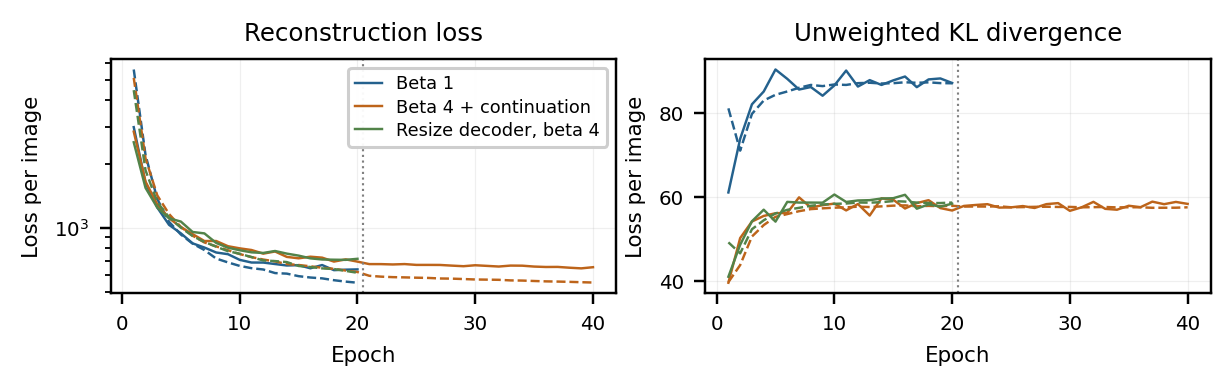


### Archived prior samples: baseline and beta4 best checkpoints.
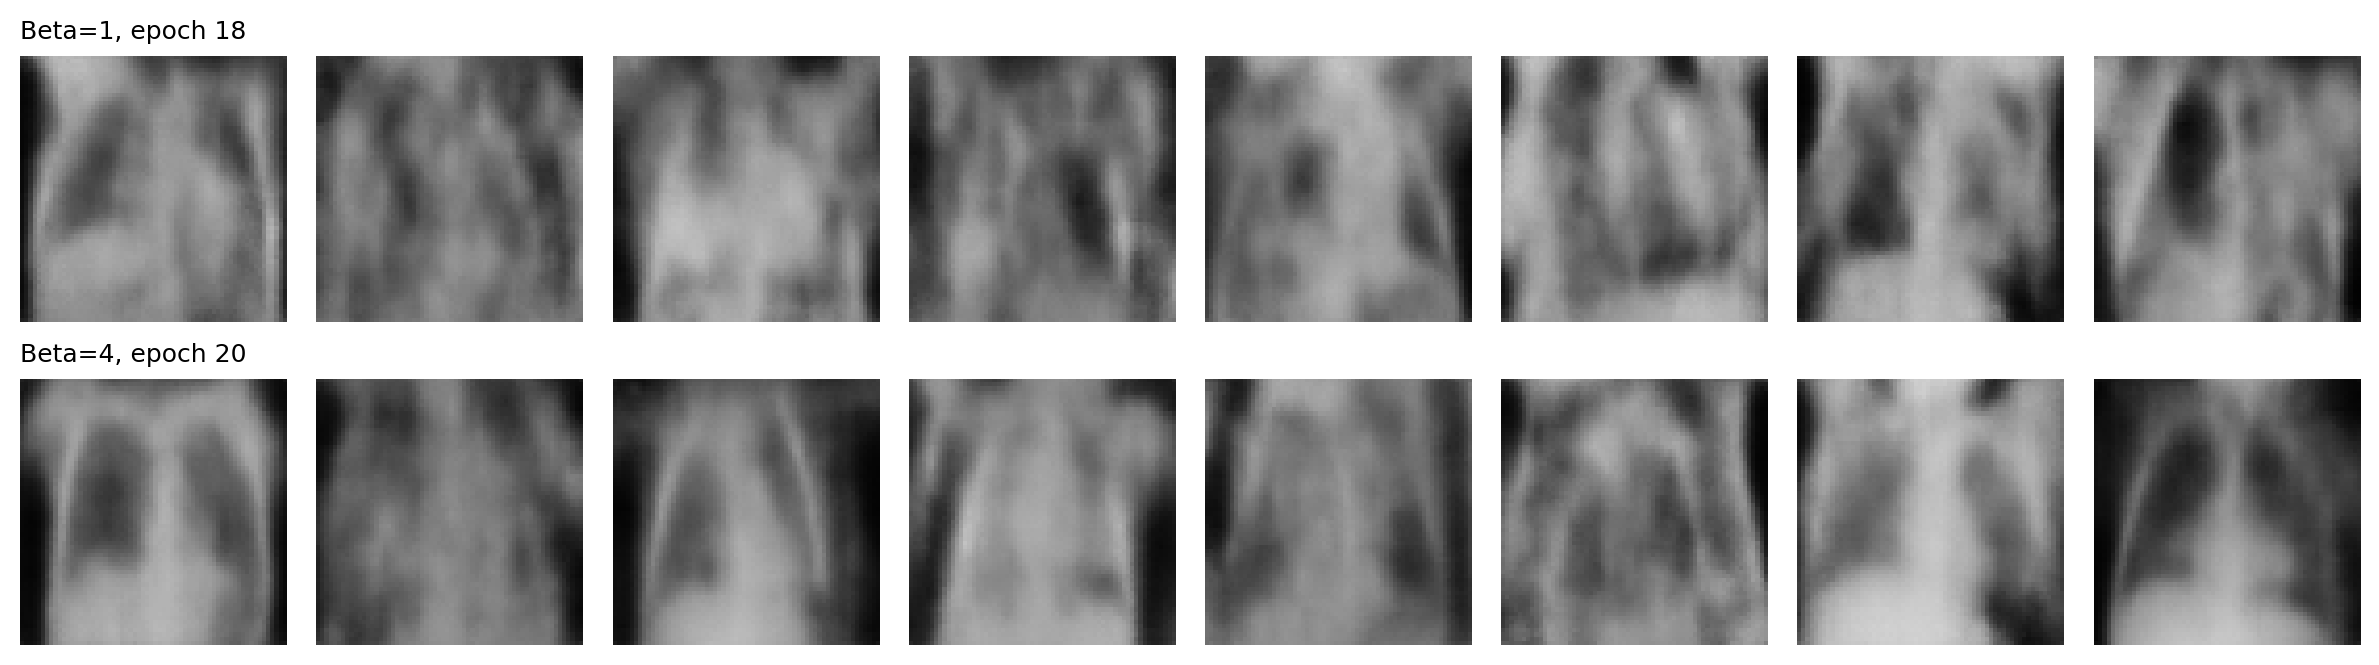


### Archived validation originals and posterior-mean reconstructions.
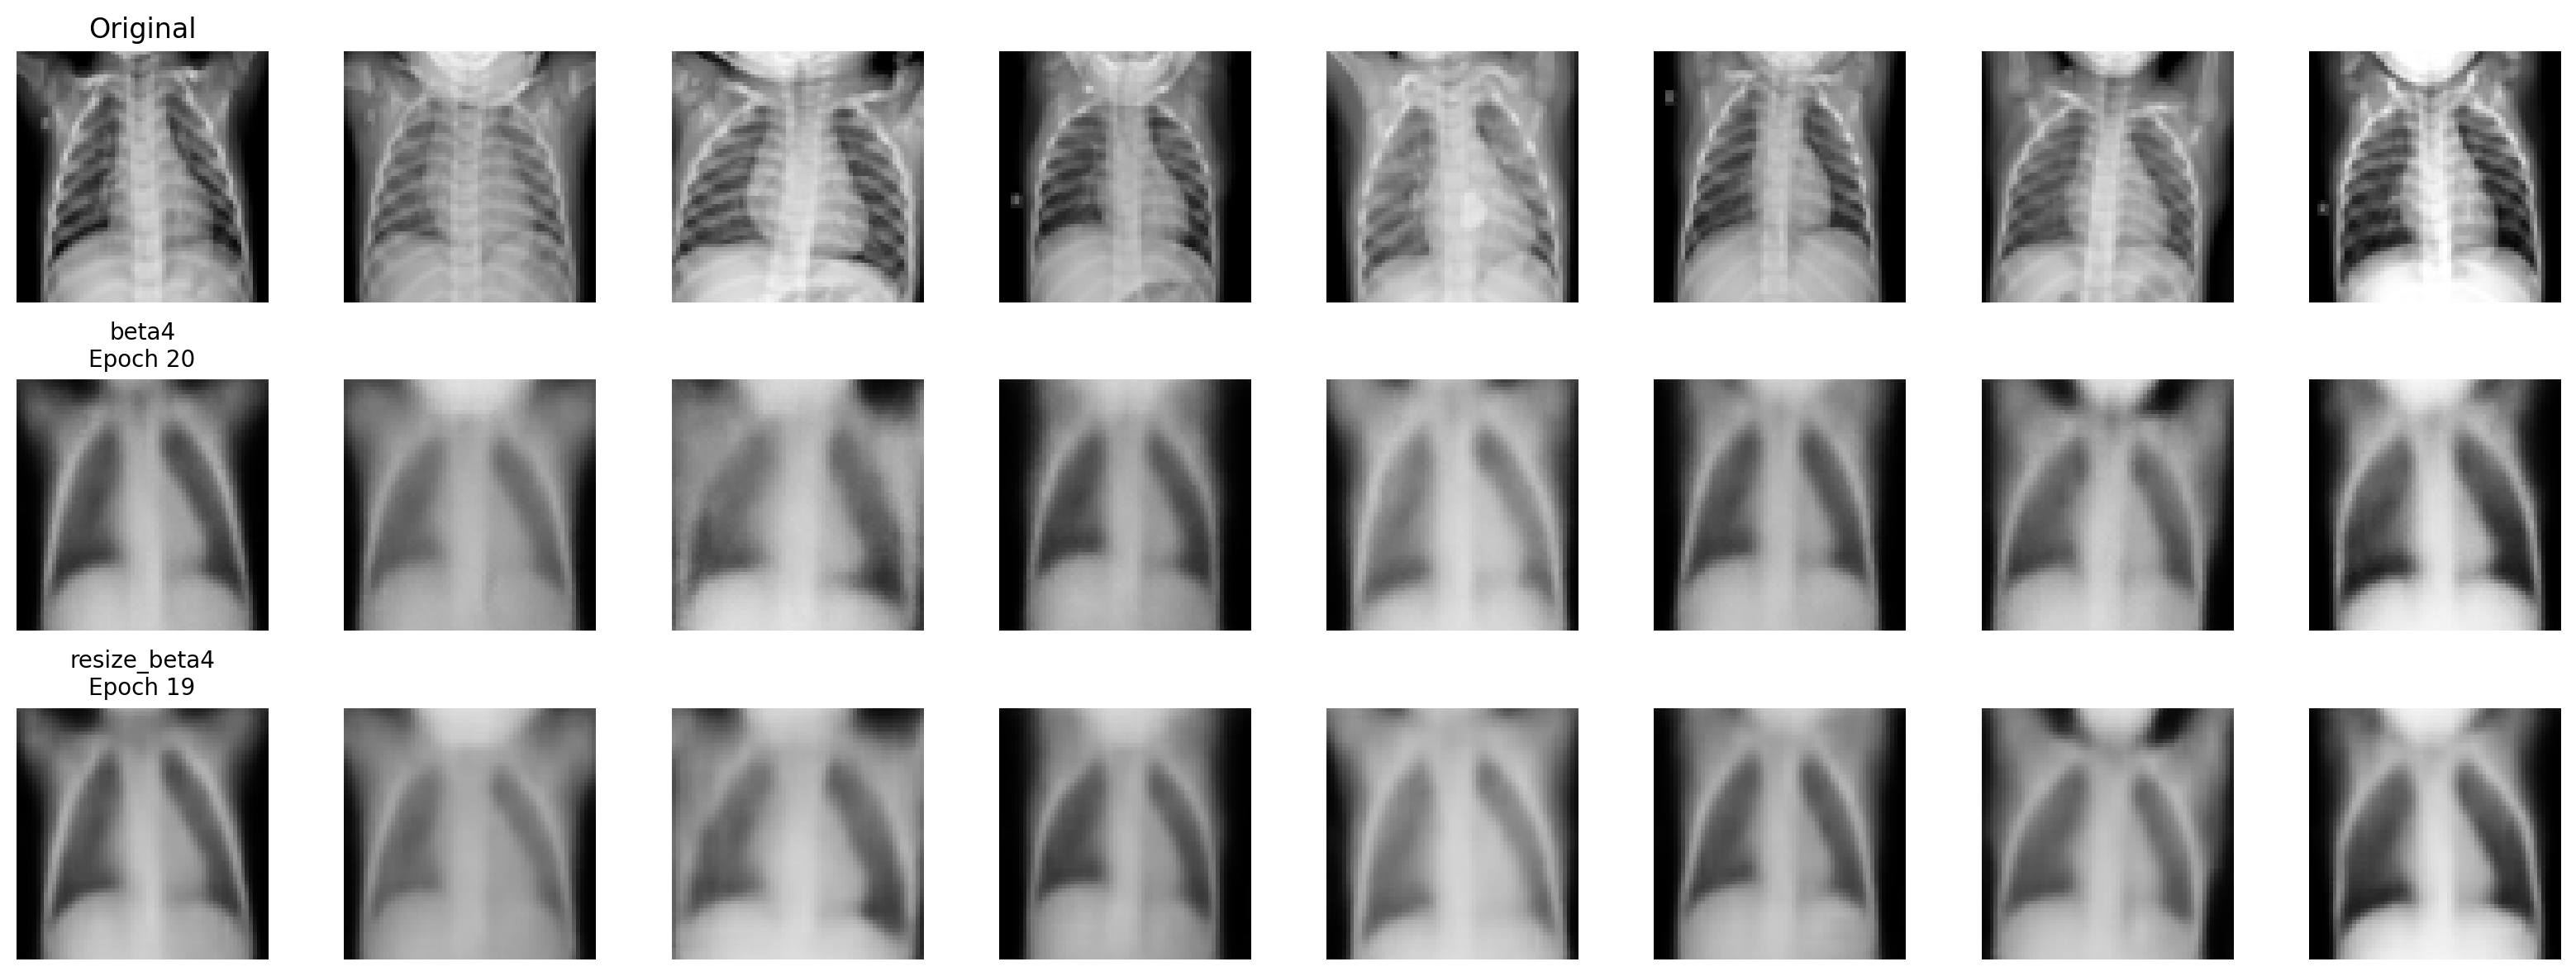


### Archived prior samples before and after continuation; identical latent inputs.
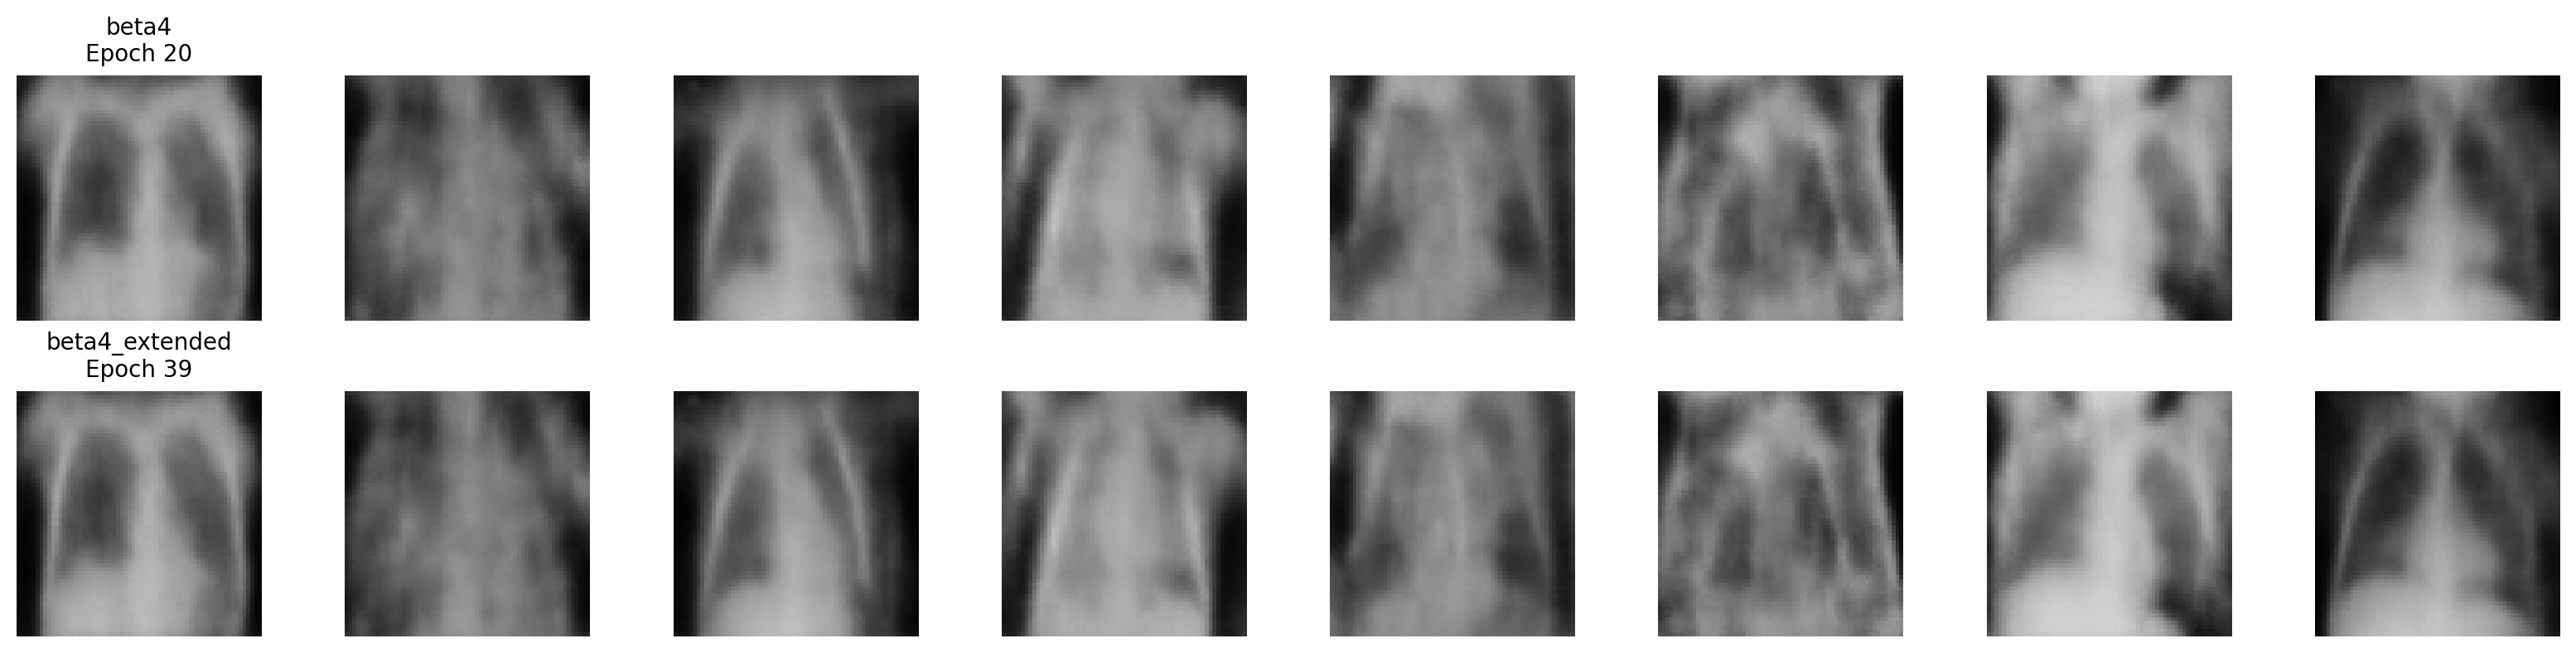


### Earlier exploratory test-reference evaluation

| Experiment | Checkpoint epoch | Test-reference FID | Inception Score |
|---|---:|---:|---:|
| Baseline, beta 1 | 18 | 279.2257 | 1.3944 |
| Beta 4 | 20 | 255.2344 | 1.5989 |

These evaluations use 624 real test images and 624 generated images. They were observed before
later tuning, so the test set is not an untouched final benchmark. They are distinct from the
517-image validation evaluation above. No recorded Inception Score or test-reference FID is
available for the beta-4 continuation.

## 7. Additional controlled beta sweep

The standard decoder was also trained with beta values 0.1, 0.3, and 1.0 for 40 epochs each.
All three runs start from the same seeded weights. Adam uses 0.001 for epochs 1-20 and 0.0003
for epochs 21-40. Input images are preprocessed once and cached to reduce disk decoding time.
The architecture, pixel likelihood scaling, and train/validation split match the original model.

This sweep uses fixed seed-2027 posterior noise for validation, independent of training RNG.
The original experiments used posterior noise from the global RNG; their validation-loss selection
procedures are therefore not identical. Generation FID uses the same validation reference,
latent bank, and feature pipeline. Checkpoints still minimize the within-run validation objective.

The companion script contains the sweep's training, checkpointing, evaluation, and figure export.
It is optional; the recorded results below do not require rerunning it.


In [ ]:
if RUN_BETA_SWEEP:
    import importlib.util

    script_path = Path("hw1_beta_sweep.py")
    if not script_path.is_file():
        raise FileNotFoundError("Upload hw1_beta_sweep.py next to this notebook before running the sweep.")
    spec = importlib.util.spec_from_file_location("hw1_beta_sweep", script_path)
    sweep = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(sweep)
    sweep.main()
else:
    print("Additional training disabled. The recorded beta-sweep results follow.")


### Recorded sweep results

All three runs completed 40 epochs. FID and Inception Score use 517 generated images;
FID references the 517 validation images. Inception Score is computed once over the full sample,
without a split-wise standard deviation. Posterior-mean MSE is averaged over all validation pixels.

| Beta | Best epoch | Validation FID | Inception Score | Posterior-mean pixel MSE |
|---|---:|---:|---:|---:|
| 0.1 | 39 | 280.28 | 1.4317 | 0.002822 |
| 0.3 | 39 | 269.70 | 1.4944 | 0.002807 |
| 1 | 40 | 254.51 | 1.5910 | 0.002829 |

Lowering beta did not improve generation FID or produce clearly resolved ribs in this sweep.
The original beta-4 continuation remains the best recorded model by validation FID.


Additional sweep: training and validation losses

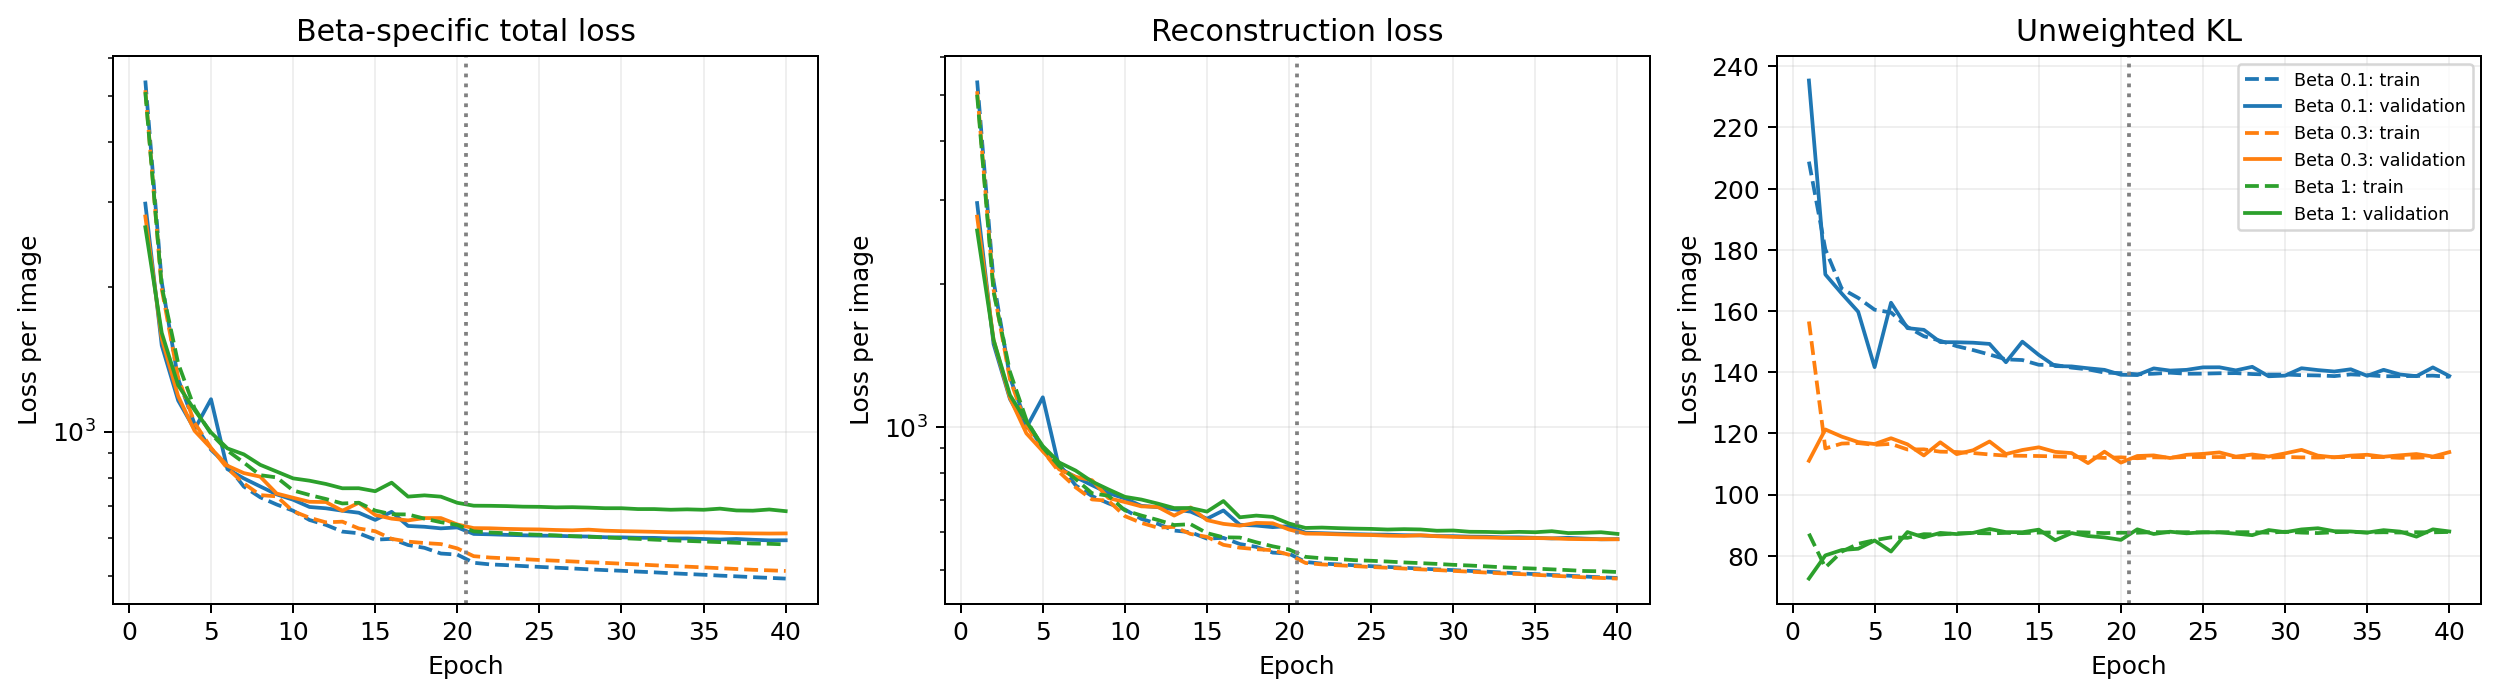


Additional sweep: prior samples with shared latent inputs

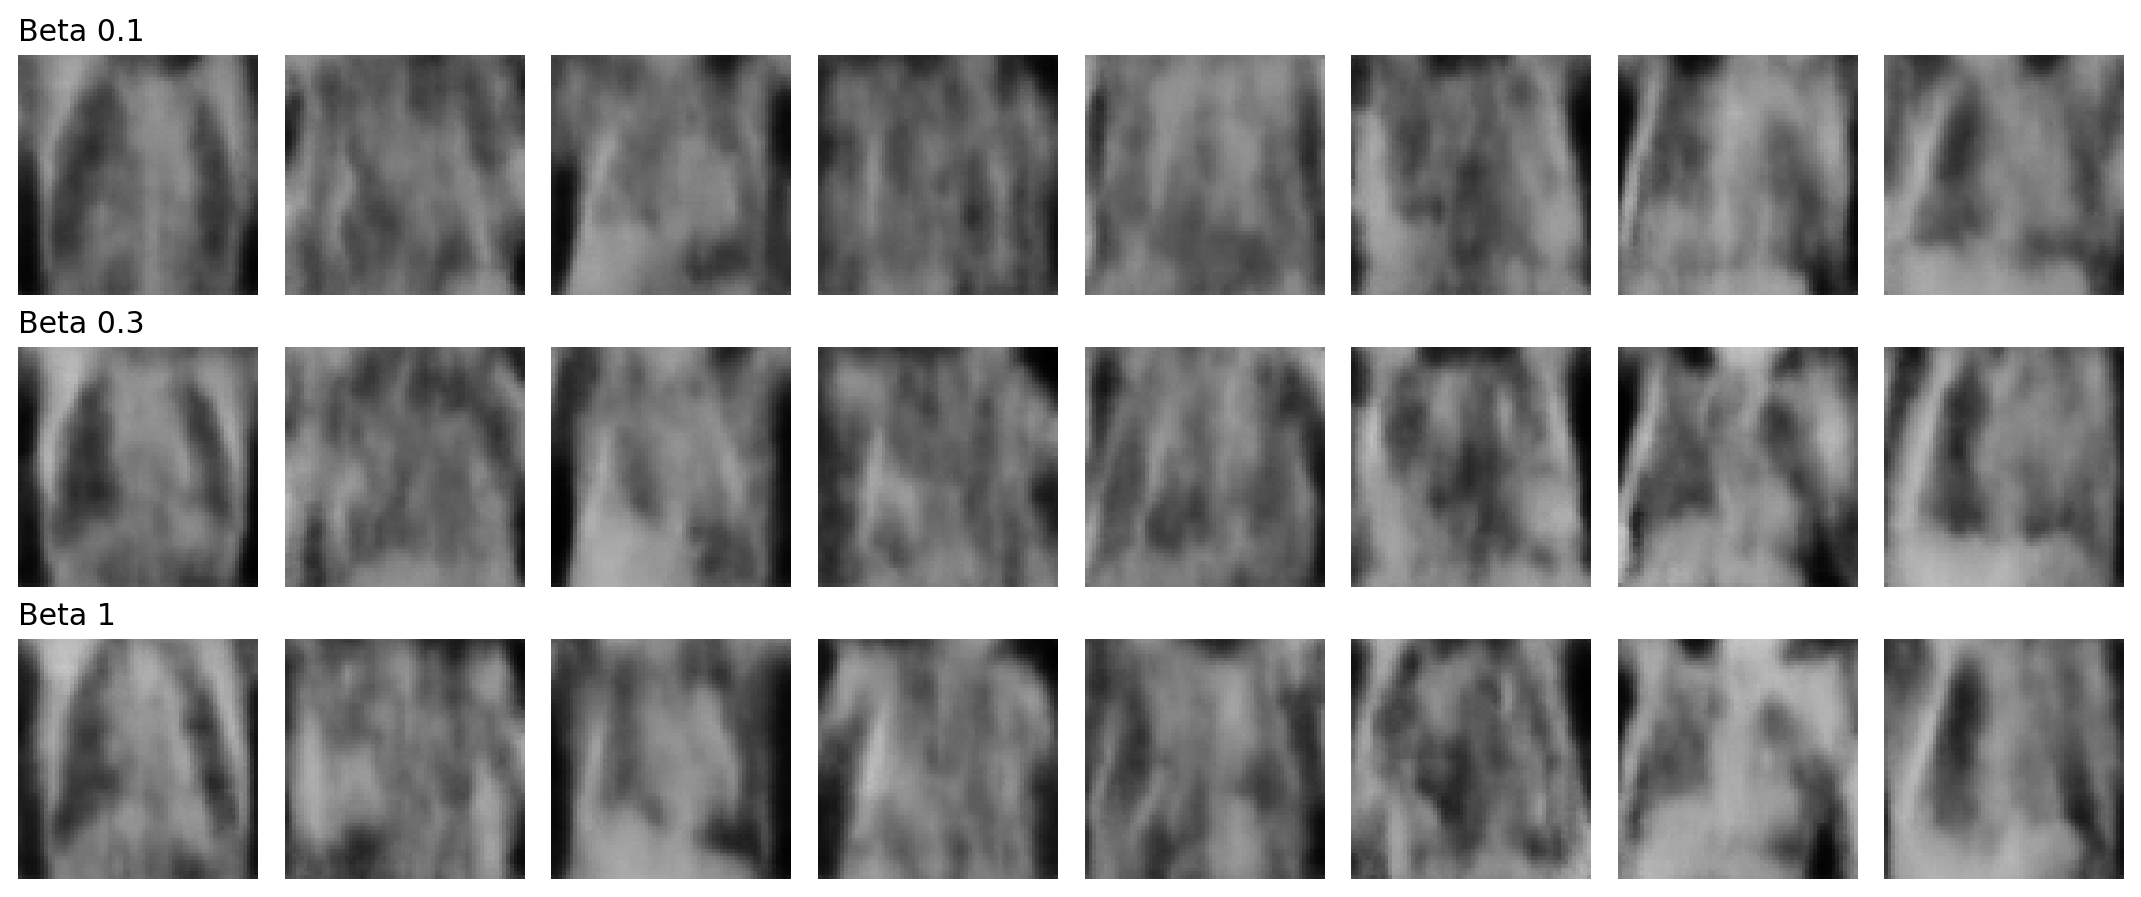


Additional sweep: validation originals and posterior-mean reconstructions

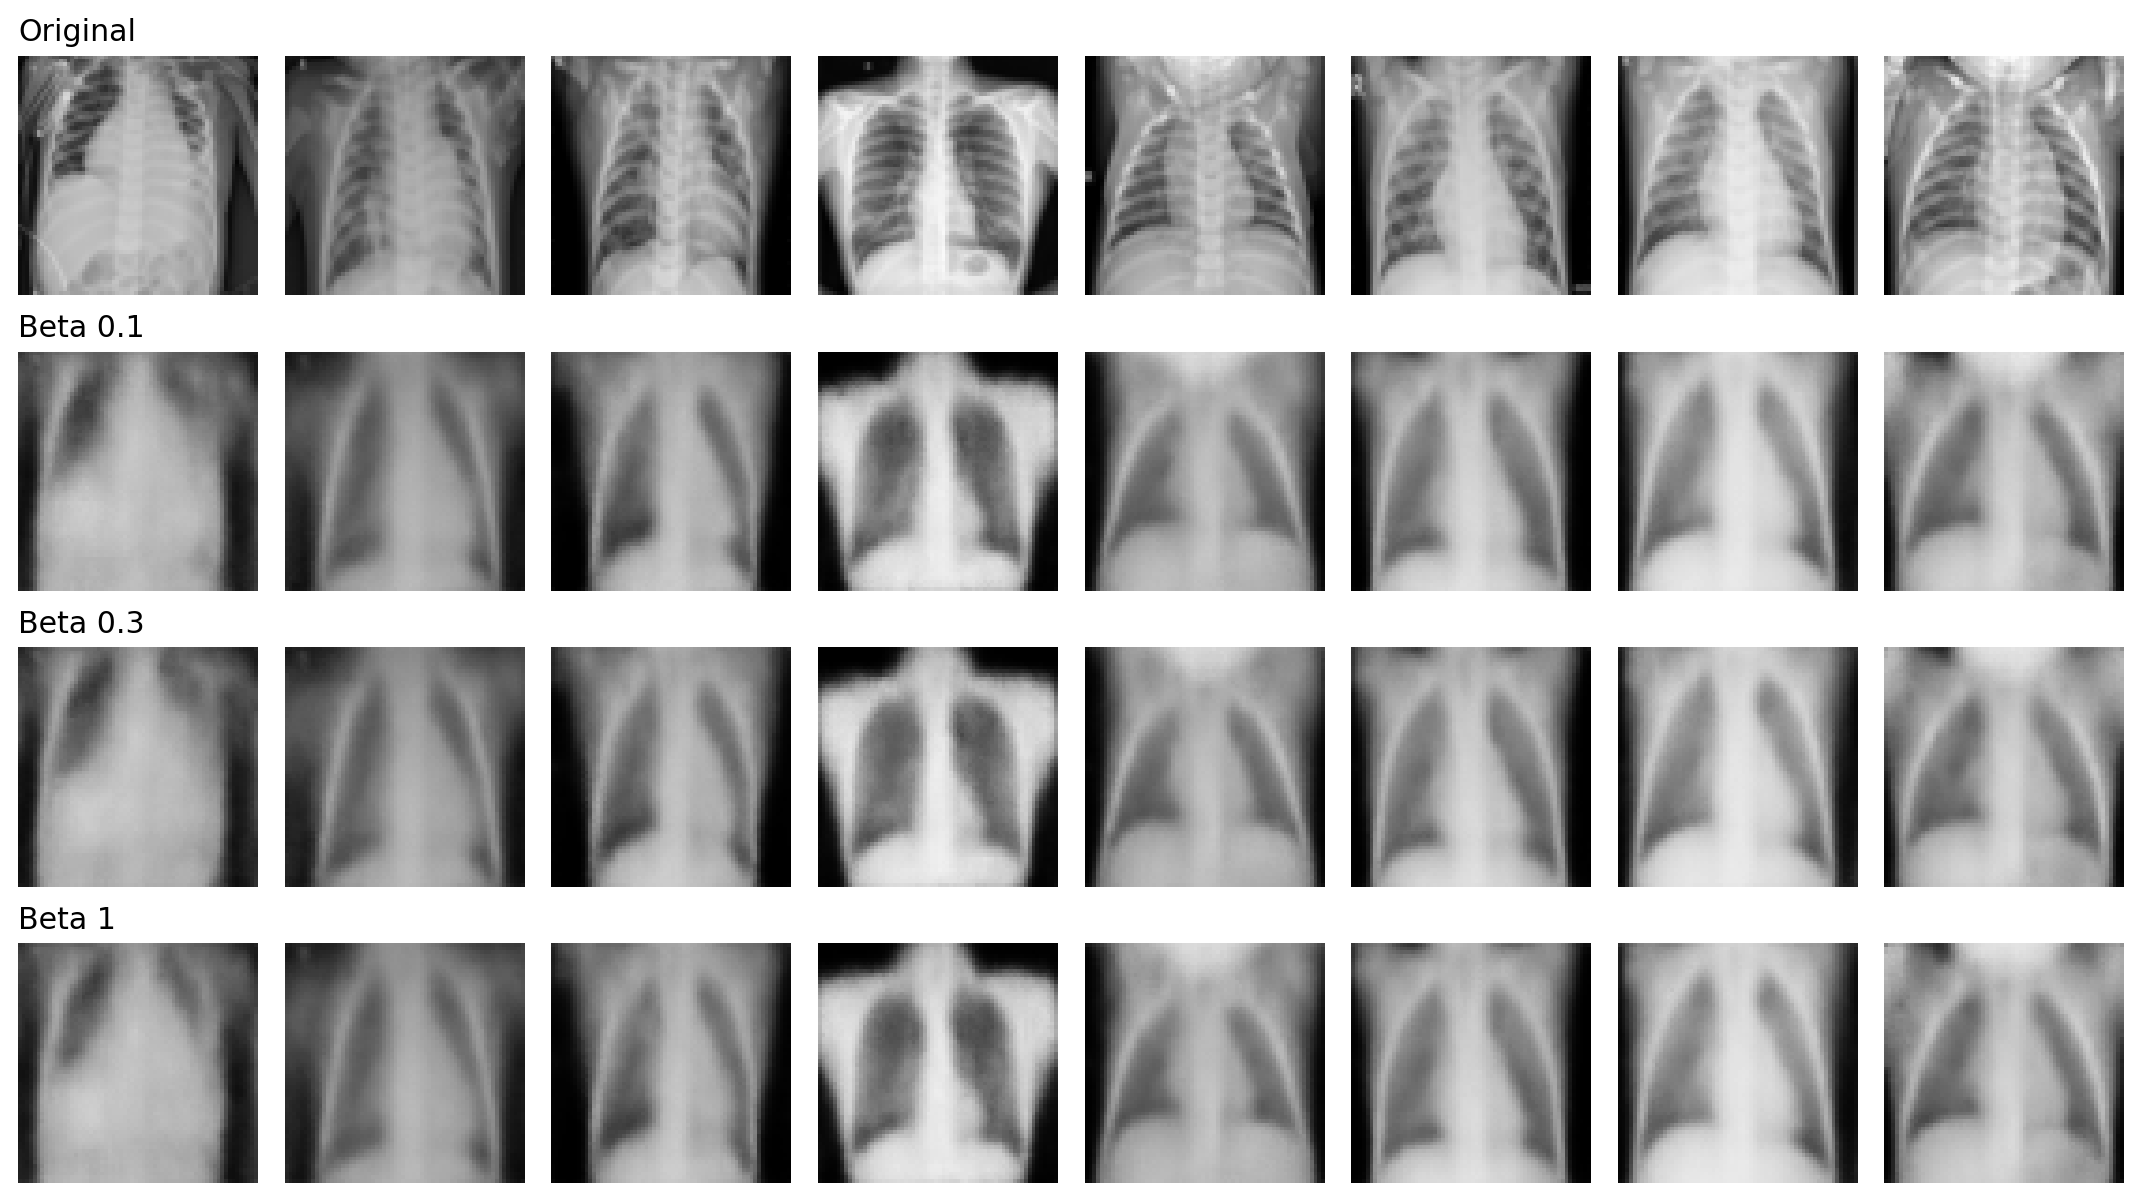


## 8. Discussion

Increasing beta from 1 to 4 improved generation FID in the original runs while increasing
reconstruction loss. Replacing the transposed-convolution decoder with resize-convolution did
not improve FID. Continuing beta 4 reduced validation FID from 240.17 to 229.94, but samples
remain blurred and lack reliable rib detail. Duration and learning rate changed together, so
their individual effects are not isolated. The additional low-beta sweep did not improve the result.

The 64 x 64 inputs retain visible ribs; resizing alone does not explain the reconstruction blur.
All experiments use one seed. FID is estimated from only 517 images with an ImageNet feature
extractor, so these results do not establish statistical significance or clinical utility.
Different feature extractors, preprocessing, and sample counts can produce different FID values.

## References

- Kingma and Welling, *Auto-Encoding Variational Bayes*: https://arxiv.org/abs/1312.6114
- Chest X-ray dataset: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
- Ignite FID and Inception Score tutorial: https://pytorch-ignite.ai/blog/gan-evaluation-with-fid-and-is/
